In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             balanced_accuracy_score, f1_score, roc_auc_score,
                             average_precision_score)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from optuna.samplers import TPESampler
import optuna
from cross_validation_utils import (
    CV_PROTOCOL, split_summary, evaluate_cv, nested_cv,
    print_cv_metrics, summary_row, save_cv_result
)


c:\Users\Mikhael\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('PIDD_diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [6]:
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [7]:
df['Outcome'].value_counts(normalize=True)*100

Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64

In [8]:
cols_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Nol pada fitur-fitur ini menandakan nilai klinis yang tidak tercatat.
# Hanya ubah menjadi NaN di sini; imputasi dipelajari dari data train di dalam pipeline.
df[cols_fix] = df[cols_fix].replace(0, np.nan)
df[cols_fix].isna().sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

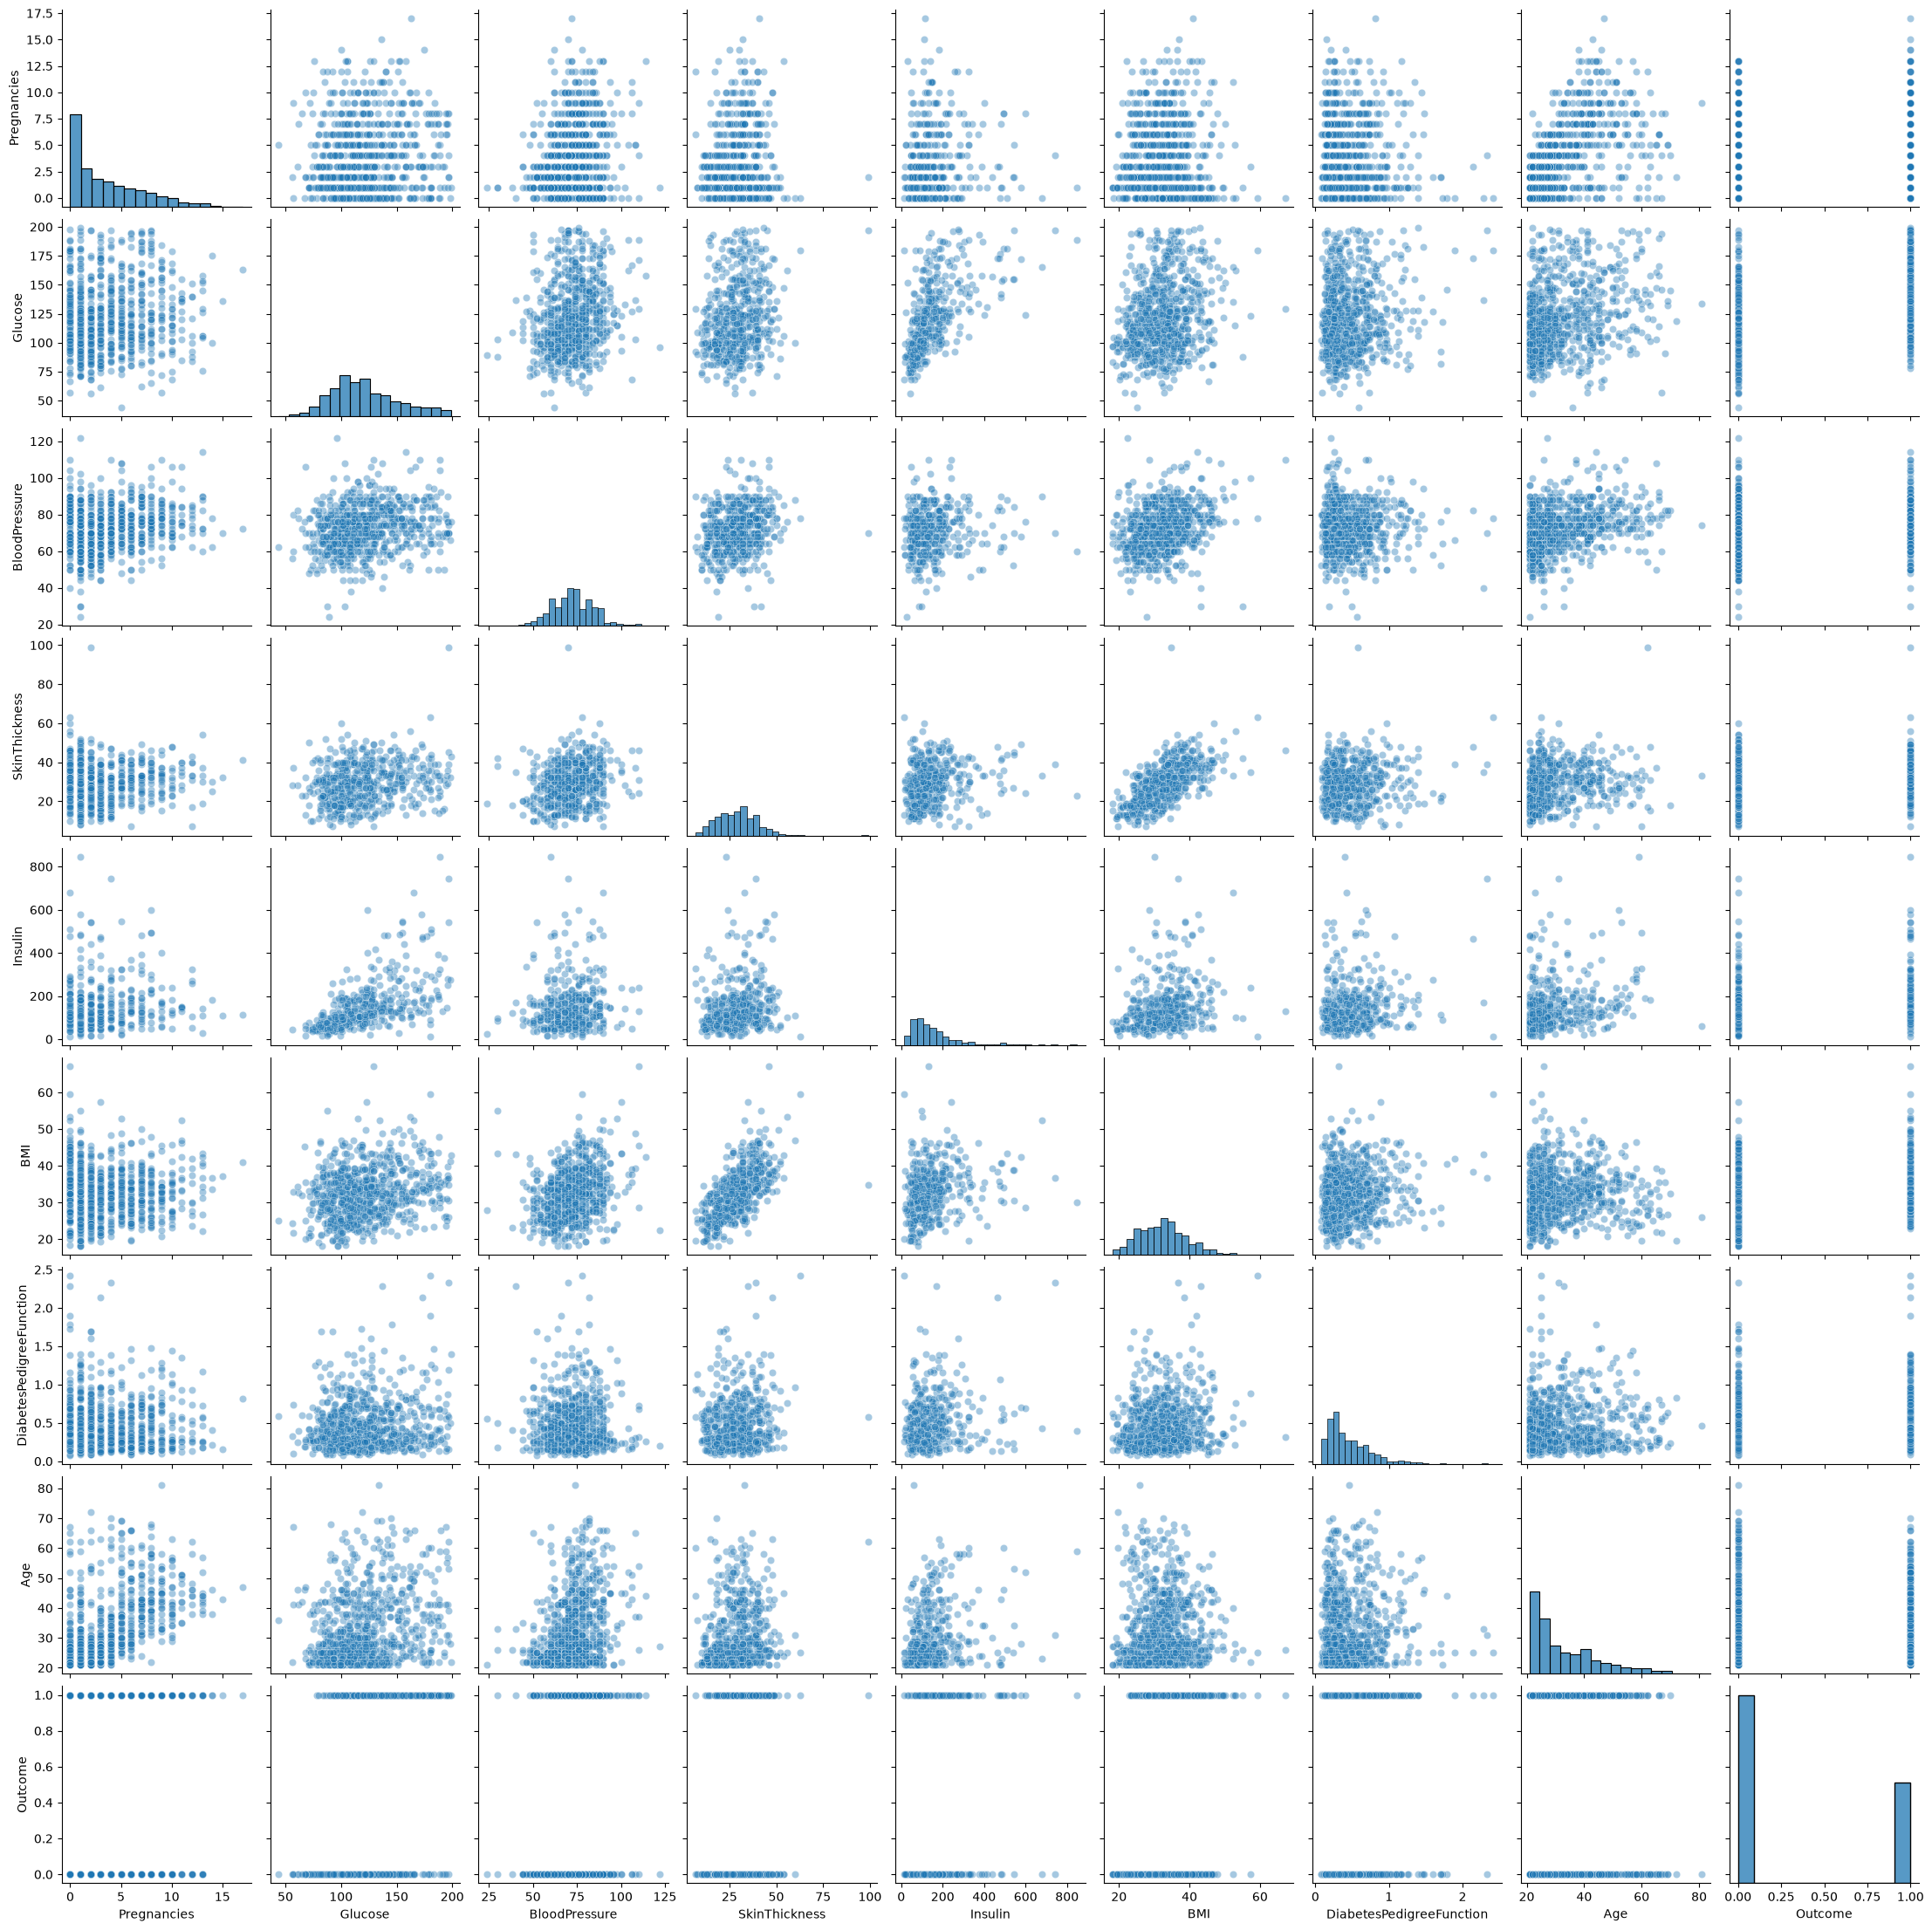

In [9]:
sns.pairplot(df, kind='scatter', plot_kws={'alpha':0.4})

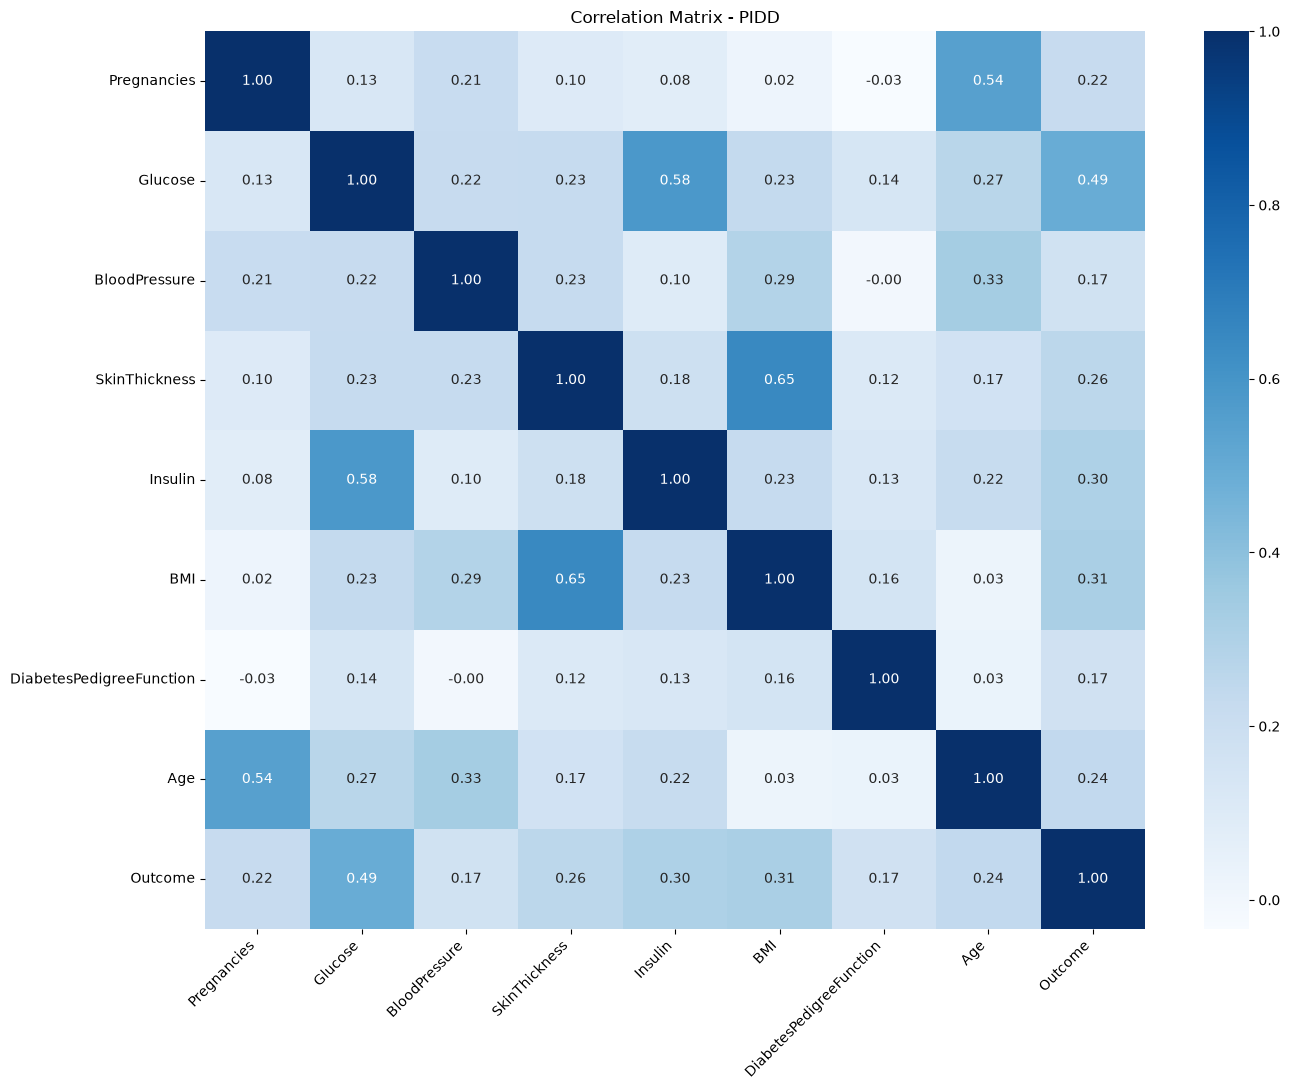

In [10]:
plt.figure(figsize=(14, 11))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='Blues')
plt.xticks(rotation=45, ha='right')
plt.title('Correlation Matrix - PIDD')
plt.tight_layout()
plt.show()

In [11]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

In [12]:
RANDOM_STATE = 42

N_SPLITS = 5

outer_cv = StratifiedKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)
groups = None


# Seluruh fold dipakai; setiap baris menjadi validation tepat sekali.
split_summary(X, y, outer_cv, groups)


,Fold,Train,Validation,Positif train,Positif validation
0,1,614,154,214,54
1,2,614,154,214,54
2,3,614,154,214,54
3,4,615,153,215,53
4,5,615,153,215,53


In [13]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(xgb_params):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(sampling_strategy='minority', random_state=RANDOM_STATE)),
        ('xgb', XGBClassifier(
            objective='binary:logistic',
            eval_metric='logloss',
            tree_method='hist',
            device='cuda',
            random_state=RANDOM_STATE,
            n_jobs=1,
            **xgb_params
        ))
    ])

In [14]:
baseline_params = {
    'max_depth': 3,
    'learning_rate': 0.1,
    'n_estimators': 100,
    'reg_alpha': 0.0,
    'reg_lambda': 1.0
}

In [15]:
baseline_pipeline = make_pipeline(baseline_params)
baseline_cv = evaluate_cv(
    make_pipeline, baseline_params, X, y, outer_cv, groups
)


Outer fold 1/5: train=614, validation=154
Outer fold 2/5: train=614, validation=154
Outer fold 3/5: train=614, validation=154


c:\Users\Mikhael\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\core.py:569: UserWarning: [12:15:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Outer fold 4/5: train=615, validation=153
Outer fold 5/5: train=615, validation=153


In [16]:
# Prediksi out-of-fold: bukan prediksi pada data latih.
y_pred = baseline_cv['prediction']
y_proba = baseline_cv['probability']


In [17]:
print_cv_metrics(baseline_cv)
print('\nClassification Report (OOF Predictions):')
print(classification_report(y, y_pred, zero_division=0))


Cross-Validation Results (Mean +/- Std):
Accuracy          : 0.7356 +/- 0.0143
Balanced Accuracy : 0.7286 +/- 0.0214
Precision         : 0.6042 +/- 0.0213
Recall            : 0.7051 +/- 0.0585
Specificity       : 0.7520 +/- 0.0277
F1                : 0.6498 +/- 0.0276
ROC-AUC           : 0.8237 +/- 0.0196
PR-AUC            : 0.7024 +/- 0.0154

Classification Report (OOF Predictions):
              precision    recall  f1-score   support

           0       0.83      0.75      0.79       500
           1       0.60      0.71      0.65       268

    accuracy                           0.74       768
   macro avg       0.72      0.73      0.72       768
weighted avg       0.75      0.74      0.74       768



Combined OOF confusion matrix (5 folds): 768 samples.


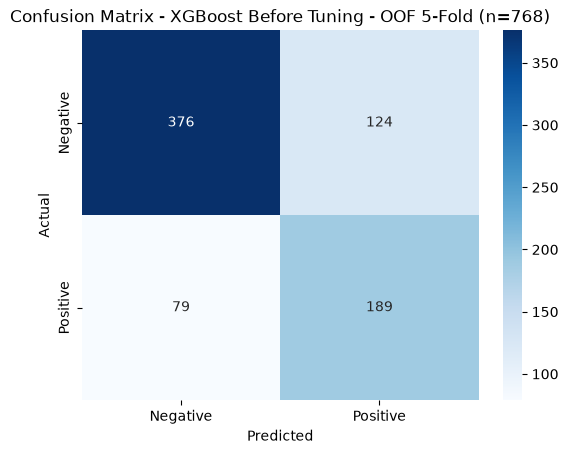

In [18]:
# Confusion matrix gabungan prediksi OOF seluruh outer folds.
# Setiap baris diuji sekali; skor utama tetap mean +/- std antar-fold.
print(f'Combined OOF confusion matrix ({N_SPLITS} folds): {len(y)} samples.')

sns.heatmap(confusion_matrix(y, y_pred), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'])
plt.title(f'Confusion Matrix - XGBoost Before Tuning - OOF {N_SPLITS}-Fold (n={len(y)})')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [19]:
def objective(trial, X_train=X, y_train=y, cv=cv, groups_train=groups):
    trial_params = {
        'max_depth': trial.suggest_int('max_depth', 2, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.30, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 100, 600, step=50),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0, step=0.1),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0, step=0.1),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0, step=0.25),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-6, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 20.0, log=True)
    }
    pipeline = make_pipeline(trial_params)
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring='f1', n_jobs=1
    )
    return scores.mean()

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 50

# Evaluasi seluruh outer folds; tuning hanya melihat inner training folds.
tuned_cv = nested_cv(
    objective, make_pipeline, X, y, outer_cv, cv,
    n_trials=N_TRIALS, groups=groups, random_state=RANDOM_STATE
)

# Cari parameter model final pada seluruh data setelah evaluasi selesai.
# Model refit ini untuk LIME/deployment, bukan untuk menghitung skor OOF.
study = optuna.create_study(
    direction='maximize', sampler=TPESampler(seed=RANDOM_STATE)
)
study.optimize(objective, n_trials=N_TRIALS)

Outer fold 1/5: train=614, validation=154
Outer fold 2/5: train=614, validation=154
Outer fold 3/5: train=614, validation=154
Outer fold 4/5: train=615, validation=153
Outer fold 5/5: train=615, validation=153


In [20]:
print("Best Params:", study.best_params)
print(f"Best mean CV F1: {study.best_value:.4f}")

# Simpan hasil tuning agar otomatis digunakan notebook perbandingan.
import json
from pathlib import Path

params_path = Path('best_params_pidd.json')
tuning_results = (
    json.loads(params_path.read_text(encoding='utf-8'))
    if params_path.exists() else {}
)
# Simpan prediksi dan metrik outer folds untuk notebook komparasi.
cv_result_file = save_cv_result(
    tuned_cv, X, y, groups,
    Path('cv_results/xgboost_pidd.json.gz'), study.best_params
)
outer_scores = summary_row(tuned_cv)
tuning_results['XGBoost'] = {
    'params': study.best_params,
    'cv_f1': float(study.best_value),
    'outer_cv_f1': outer_scores['F1'],
    'outer_cv_f1_std': outer_scores['F1 Std'],
    'evaluation_protocol': CV_PROTOCOL,
    'outer_n_splits': N_SPLITS,
    'inner_n_splits': N_SPLITS,
    'cv_result_file': cv_result_file
}
params_path.write_text(
    json.dumps(tuning_results, indent=2), encoding='utf-8'
)
print(f'Best XGBoost parameters saved to: {params_path.resolve()}')

# Refit pada seluruh data setelah evaluasi; skor tetap dari prediksi OOF.
best_pipeline = make_pipeline(study.best_params)
best_pipeline.fit(X, y)

Best Params: {'max_depth': 5, 'learning_rate': 0.026638917203111404, 'n_estimators': 150, 'min_child_weight': 10, 'subsample': 0.7, 'colsample_bytree': 0.9, 'gamma': 4.0, 'reg_alpha': 1.9465204306303465, 'reg_lambda': 6.074704952365206}
Best mean CV F1: 0.7134
Best XGBoost parameters saved to: D:\TELKOM\PENPRO\Diabetes\Model\temp\best_params_pidd.json


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None


In [21]:
optuna_prediction = tuned_cv['prediction']
optuna_proba = tuned_cv['probability']

print_cv_metrics(tuned_cv)
print('\nClassification Report (OOF Predictions):')
print(classification_report(y, optuna_prediction, zero_division=0))


Cross-Validation Results (Mean +/- Std):
Accuracy          : 0.7656 +/- 0.0262
Balanced Accuracy : 0.7636 +/- 0.0336
Precision         : 0.6377 +/- 0.0308
Recall            : 0.7572 +/- 0.0605
Specificity       : 0.7700 +/- 0.0158
F1                : 0.6920 +/- 0.0416
ROC-AUC           : 0.8372 +/- 0.0268
PR-AUC            : 0.7234 +/- 0.0486

Classification Report (OOF Predictions):
              precision    recall  f1-score   support

           0       0.86      0.77      0.81       500
           1       0.64      0.76      0.69       268

    accuracy                           0.77       768
   macro avg       0.75      0.76      0.75       768
weighted avg       0.78      0.77      0.77       768



In [22]:
baseline_scores = summary_row(baseline_cv)
tuned_scores = summary_row(tuned_cv)

for metric in ['Accuracy', 'F1']:
    print(f"Baseline {metric}: {baseline_scores[metric]:.4f} +/- "
          f"{baseline_scores[f'{metric} Std']:.4f}")
    print(f"Tuned {metric}   : {tuned_scores[metric]:.4f} +/- "
          f"{tuned_scores[f'{metric} Std']:.4f}")


Baseline Accuracy: 0.7356 +/- 0.0143
Tuned Accuracy   : 0.7656 +/- 0.0262
Baseline F1: 0.6498 +/- 0.0276
Tuned F1   : 0.6920 +/- 0.0416


Combined OOF confusion matrix (5 folds): 768 samples.


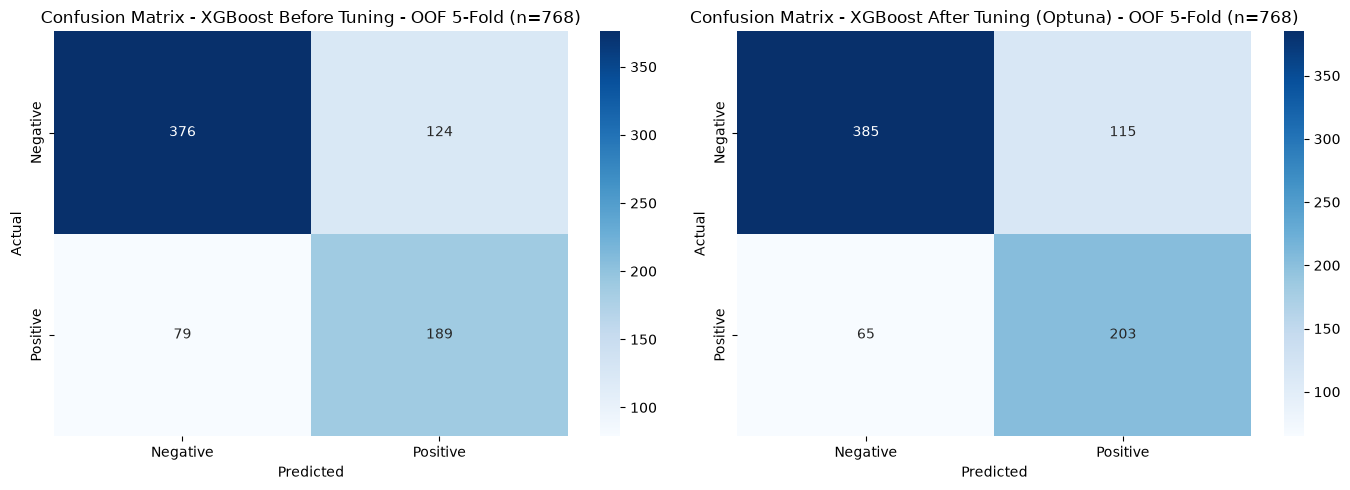

In [23]:
# Confusion matrix gabungan prediksi OOF seluruh outer folds.
# Setiap baris diuji sekali; skor utama tetap mean +/- std antar-fold.
assert np.array_equal(baseline_cv['fold_id'], tuned_cv['fold_id']), \
    'Fold baseline dan tuning harus identik.'
print(f'Combined OOF confusion matrix ({N_SPLITS} folds): {len(y)} samples.')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(confusion_matrix(y, y_pred), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'], ax=ax[0])
ax[0].set_title(f"Confusion Matrix - XGBoost Before Tuning - OOF {N_SPLITS}-Fold (n={len(y)})")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")


sns.heatmap(confusion_matrix(y, optuna_prediction), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'], ax=ax[1])
ax[1].set_title(f"Confusion Matrix - XGBoost After Tuning (Optuna) - OOF {N_SPLITS}-Fold (n={len(y)})")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [24]:
# Variasi antar-fold; bukan bootstrap test set atau confidence interval.
fold_scores = tuned_cv['folds']['Accuracy'].to_numpy()
mean_acc = fold_scores.mean()
std_acc = fold_scores.std(ddof=1)

print(f'Mean Accuracy ({N_SPLITS}-Fold CV): {mean_acc:.4f} +/- {std_acc:.4f}')
tuned_cv['folds'].drop(columns='Best Params').round(4)


Mean Accuracy (5-Fold CV): 0.7656 +/- 0.0262


,Fold,Train Rows,Validation Rows,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,Fit seconds,Inner CV F1
0,1,614,154,0.7792,0.7874,0.6471,0.8148,0.76,0.7213,0.8530,0.6922,74.4229,0.6775
1,2,614,154,0.7727,0.7654,0.6557,0.7407,0.79,0.6957,0.8620,0.8005,71.4453,0.7031
2,3,614,154,0.7792,0.7789,0.6562,0.7778,0.78,0.7119,0.8502,0.7419,83.0840,0.6923
3,4,615,153,0.7778,0.7812,0.6462,0.7925,0.77,0.7119,0.8243,0.6979,73.3817,0.6817
4,5,615,153,0.7190,0.7052,0.5833,0.6604,0.75,0.6195,0.7964,0.6845,47.7168,0.7362


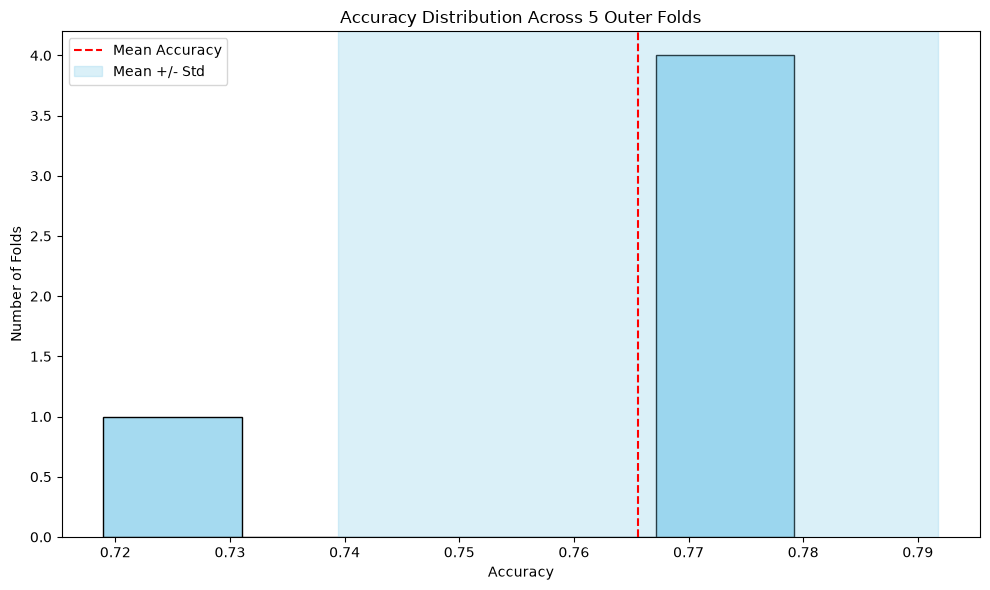

In [25]:
plt.figure(figsize=(10, 6))
sns.histplot(fold_scores, bins=N_SPLITS, color='skyblue')
plt.axvline(mean_acc, color='red', linestyle='--', label='Mean Accuracy')
plt.axvspan(mean_acc - std_acc, mean_acc + std_acc,
            color='skyblue', alpha=0.3, label='Mean +/- Std')
plt.title(f'Accuracy Distribution Across {N_SPLITS} Outer Folds')
plt.xlabel('Accuracy')
plt.ylabel('Number of Folds')
plt.legend()
plt.tight_layout()
plt.show()


In [26]:
from lime.lime_tabular import LimeTabularExplainer
import random

In [27]:
# LIME menggunakan model final yang sudah direfit pada seluruh data.
X_imputed = pd.DataFrame(
    best_pipeline.named_steps['imputer'].transform(X),
    columns=X.columns, index=X.index
)

explainer = LimeTabularExplainer(
    training_data=X_imputed.values,     
    feature_names=X.columns.tolist(),   
    class_names=['Negative', 'Positive'], 
    mode='classification',                    
    random_state=42
)

In [28]:
rng_lime = np.random.default_rng(RANDOM_STATE)
sample_index = int(rng_lime.integers(0, len(X)))
sample_data = X.iloc[sample_index]
sample_data_imputed = best_pipeline.named_steps['imputer'].transform(
    sample_data.to_frame().T
)[0]

def lime_predict(data):
    data_df = pd.DataFrame(data, columns=X.columns)
    return best_pipeline.predict_proba(data_df)

exp = explainer.explain_instance(
    data_row=sample_data_imputed,
    predict_fn=lime_predict,
    num_features=5
)

In [29]:
from IPython.display import HTML, display

html_output = exp.as_html(show_table=True, show_all=False)
actual_label = 'Positive' if y.iloc[sample_index] == 1 else 'Negative'
print(f'Actual value for sample index {sample_index}: {actual_label}')
display(HTML(html_output))


Actual value for sample index 68: Negative


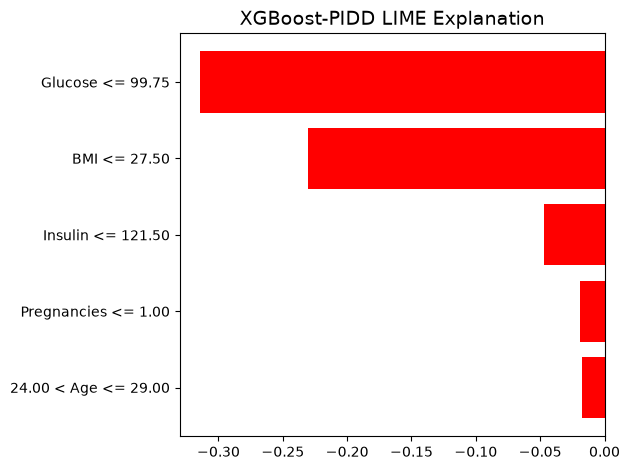

LIME image saved to: D:\TELKOM\PENPRO\Diabetes\Model\temp\lime_xgboost_pidd.png


In [30]:
from pathlib import Path

output_path = Path('lime_xgboost_pidd.png')

label = exp.available_labels()[0]
fig = exp.as_pyplot_figure(label=label)
fig.axes[0].set_title('XGBoost-PIDD LIME Explanation', fontsize=14)

fig.tight_layout()
fig.savefig(
    output_path,
    format='png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
print(f'LIME image saved to: {output_path.resolve()}')
